<h1>TensorFlow Convolutional Autoencoder</h1>


Importing libraries:

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

print(tf.__version__)
!python --version

2.15.0
Python 3.10.12


Loading and procesing datasets

In [ ]:
(train_images,_), _ = tf.keras.datasets.mnist.load_data()

train_images = train_images.astype('float32') / 255.
train_images = train_images[..., tf.newaxis]
print(train_images.shape)

train_size = 60000
batch_size = 500

train_dataset = (tf.data.Dataset.from_tensor_slices(train_images).shuffle(train_size).batch(batch_size))


11490434/11490434 [==============================] - 0s 0us/step
(60000, 28, 28, 1)


Visualize the data


(500, 28, 28, 1)


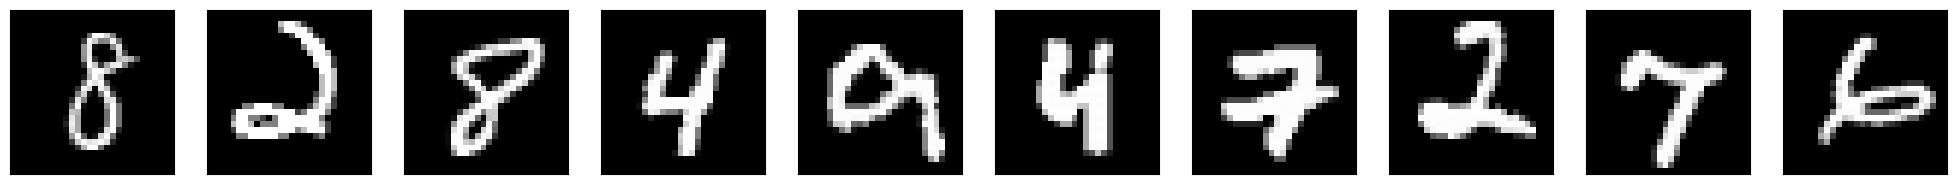

In [ ]:
dataiter = iter(train_dataset)
images = next(dataiter)
print(images.shape)

n = 10
plt.figure(figsize=(25, 4))
for i in range(n):
    ax = plt.subplot(1, n, i + 1)
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
    plt.imshow(tf.squeeze(images[i]), cmap='gray')

#plt.show()

Building the Encode-Decode network


In [ ]:
class AutoEncoder(tf.keras.Model):
  #Convolutional autoencoder

  def __init__(self):
    super(AutoEncoder, self).__init__()
    self.encoder = tf.keras.Sequential([
      tf.keras.layers.Input(shape=(28, 28, 1)),
      tf.keras.layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
      tf.keras.layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='valid'),
      tf.keras.layers.Conv2D(4, (3, 3), activation='relu', padding='same'),
      tf.keras.layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='valid')])

    self.decoder = tf.keras.Sequential([
      tf.keras.layers.Conv2DTranspose(16, kernel_size=2, strides=2, activation='relu'),
      tf.keras.layers.Conv2DTranspose(1, kernel_size=2, strides=2, activation='sigmoid')])

  def call(self, x):
    encoded = self.encoder(x)
    decoded = self.decoder(encoded)
    return decoded

  def encode(self, x):
    return self.encoder(x)

  def decode(self, x):
    return self.decoder(x)

Configure and train the model


In [ ]:
model = AutoEncoder()
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss=tf.keras.losses.MeanSquaredError())

In [ ]:
# number of epochs to train the model
n_epochs = 25

model.fit(train_images, train_images, batch_size=batch_size ,epochs=n_epochs, shuffle=False)
model.encoder.summary()
model.decoder.summary()

#Saving the model and training parameters

#Mouting colab with the drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
base_location = '/content/drive/My Drive/Academico/CienciasEspaciales/WVU/Research/NeuralNetworks'
model.save(base_location+'/TensorFlow/MNIST_CAE/CAE_model')

Epoch 1/25
120/120 [==============================] - 6s 6ms/step - loss: 0.1541
Epoch 2/25
120/120 [==============================] - 1s 5ms/step - loss: 0.0576
Epoch 3/25
120/120 [==============================] - 1s 6ms/step - loss: 0.0491
Epoch 4/25
120/120 [==============================] - 1s 6ms/step - loss: 0.0436
Epoch 5/25
120/120 [==============================] - 1s 7ms/step - loss: 0.0342
Epoch 6/25
120/120 [==============================] - 1s 6ms/step - loss: 0.0260
Epoch 7/25
120/120 [==============================] - 1s 6ms/step - loss: 0.0216
Epoch 8/25
120/120 [==============================] - 1s 5ms/step - loss: 0.0198
Epoch 9/25
120/120 [==============================] - 1s 5ms/step - loss: 0.0181
Epoch 10/25
120/120 [==============================] - 1s 6ms/step - loss: 0.0165
Epoch 11/25
120/120 [==============================] - 1s 6ms/step - loss: 0.0152
Epoch 12/25
120/120 [==============================] - 1s 6ms/step - loss: 0.0142
Epoch 13/25
120/120 [====

Testing the Encoder part with whole test dataset to compare with cFS

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

import time
from psutil import *

In [3]:
#Getting CPU resources
print("CPU's: {}".format(cpu_count()))
print(cpu_stats())
!cat /proc/cpuinfo
print(virtual_memory())

CPU's: 2
scpustats(ctx_switches=912475, interrupts=516546, soft_interrupts=490814, syscalls=0)
processor	: 0
vendor_id	: GenuineIntel
cpu family	: 6
model		: 79
model name	: Intel(R) Xeon(R) CPU @ 2.20GHz
stepping	: 0
microcode	: 0xffffffff
cpu MHz		: 2199.998
cache size	: 56320 KB
physical id	: 0
siblings	: 2
core id		: 0
cpu cores	: 1
apicid		: 0
initial apicid	: 0
fpu		: yes
fpu_exception	: yes
cpuid level	: 13
wp		: yes
flags		: fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 clflush mmx fxsr sse sse2 ss ht syscall nx pdpe1gb rdtscp lm constant_tsc rep_good nopl xtopology nonstop_tsc cpuid tsc_known_freq pni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2apic movbe popcnt aes xsave avx f16c rdrand hypervisor lahf_lm abm 3dnowprefetch invpcid_single ssbd ibrs ibpb stibp fsgsbase tsc_adjust bmi1 hle avx2 smep bmi2 erms invpcid rtm rdseed adx smap xsaveopt arat md_clear arch_capabilities
bugs		: cpu_meltdown spectre_v1 spectre_v2 spec_store_bypass l1tf mds swapg

In [4]:
#Mouting colab with the drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
base_location = '/content/drive/My Drive/Academico/CienciasEspaciales/WVU/Research/NeuralNetworks'

#Loading the saved model
model = tf.keras.models.load_model(base_location+'/TensorFlow/MNIST_CAE/CAE_model')
model.encoder.summary()
model.decoder.summary()


Mounted at /content/drive
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 28, 28, 16)        160       
                                                                 
 max_pooling2d (MaxPooling2  (None, 14, 14, 16)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 14, 14, 4)         580       
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 7, 7, 4)           0         
 g2D)                                                            
                                                                 
Total params: 740 (2.89 KB)
Trainable params: 740 (2.89 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [21]:
_ , (test_images,_) = tf.keras.datasets.mnist.load_data()

test_images = test_images.astype('float32') / 255.
test_images = test_images[..., tf.newaxis]
print(test_images.shape)

batch_size = 1

test_size = 10000
test_dataset = (tf.data.Dataset.from_tensor_slices(test_images).shuffle(test_size).batch(batch_size))

elapsed = []
latency = 0.0
throughput = 0.0

cpu_start = Process().cpu_percent()
for data in test_dataset:
    images = data
    start = time.time()
    latent = model.encoder(images)
    end = time.time()
    elapsed.append((end - start)/batch_size)
cpu_end = Process().cpu_percent()

latency = np.sum(elapsed)/len(test_dataset)
lat_std = np.std(elapsed);
throughput = 1/latency;
cpu_usage = cpu_end - cpu_start
print('Latency: {:.6f}, Latency Std Dev: {:.6f}, Throughput: {:.2f}, CPU usage {:.6f}'.format(latency,lat_std,throughput,cpu_usage))

(10000, 28, 28, 1)
Latency: 0.003374, Latency Std Dev: 0.001670, Throughput: 296.41, CPU usage 0.000000


Testing the complete Autoencoder with one batch

(300, 4, 7, 7)
tf.Tensor(
[[[3.3544037  3.3346963  3.334695   3.3494503  3.6872818  3.3346963
   3.3346958 ]
  [3.1924691  3.1924691  3.1971512  3.2067695  2.0150747  3.1924694
   3.1924691 ]
  [3.1924691  3.1924691  3.192468   3.160097   1.046547   3.192469
   3.1924691 ]
  [3.1924691  3.1924691  3.184134   2.3754964  2.046266   3.2984722
   3.1924691 ]
  [3.1924691  3.1924691  3.1494174  1.2409256  3.262337   3.1924691
   3.1924691 ]
  [3.1924691  3.3607287  3.208054   0.28357223 3.1858783  3.1924691
   3.1924691 ]
  [3.1924696  3.279871   3.1131973  3.2527375  3.2631195  3.1924696
   3.1924682 ]]

 [[3.7006474  3.7006474  3.7006469  3.6990404  3.5205958  3.910964
   3.700647  ]
  [3.7006474  3.7006474  3.7073863  3.261553   4.085279   4.0875072
   3.700647  ]
  [3.7006474  3.7006474  3.70065    1.2197258  3.8033235  3.882062
   3.700647  ]
  [3.7006474  3.7006474  3.7368698  0.2952133  4.0926647  3.786752
   3.700647  ]
  [3.7006474  3.708058   2.7839103  2.473352   3.9514377  3.700

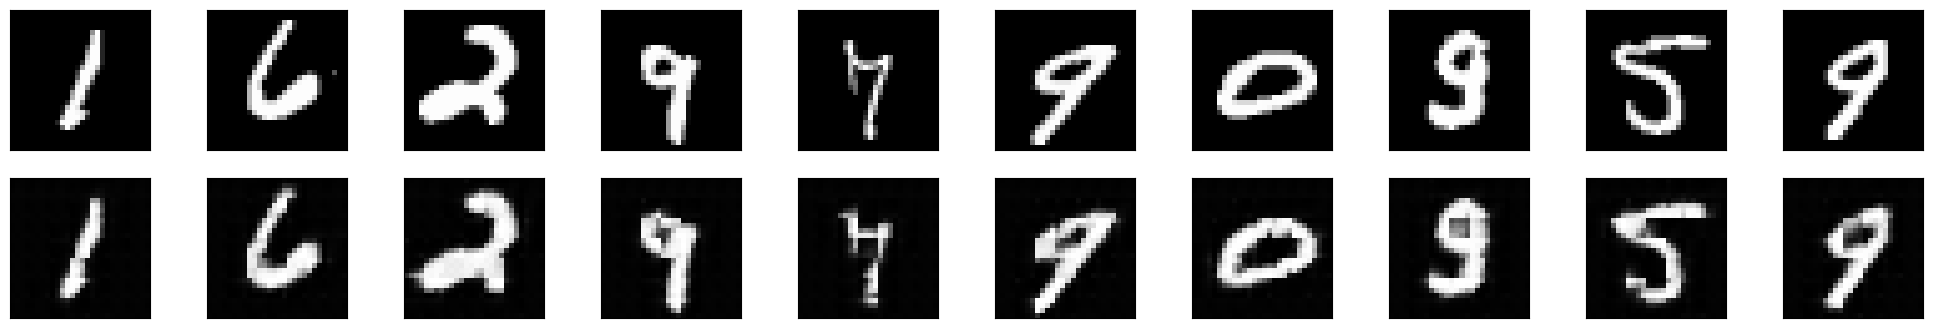

In [ ]:
# obtain one batch of test images
dataiter = iter(test_dataset)
images = next(dataiter)

latent = model.encoder(images)
lat = tf.transpose(latent, perm=[0,3,1,2])
print(lat.shape)
print(lat[0])

# get sample outputs
output = model.decoder(latent)
output = tf.transpose(output, perm=[0,3,1,2])
# prep images for display

# execute all encode-decode process instead
#output = model.predict(images)
#output = tf.transpose(output, perm=[0,3,1,2])

images = images.numpy()

# plot the first ten input images and then reconstructed images
fig, axes = plt.subplots(nrows=2, ncols=10, sharex=True, sharey=True, figsize=(25,4))

# input images on top row, reconstructions on bottom
for images, row in zip([images, output], axes):
    for img, ax in zip(images, row):
        ax.imshow(np.squeeze(img), cmap='gray')
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)


Saving the Model as TensorFlow SavedModel, and run it

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 28, 28, 16)        160       
                                                                 
 max_pooling2d (MaxPooling2  (None, 14, 14, 16)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 14, 14, 4)         580       
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 7, 7, 4)           0         
 g2D)                                                            
                                                                 
Total params: 740 (2.89 KB)
Trainable params: 740 (2.89 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
(300, 4, 7, 7)
tf.Tensor(


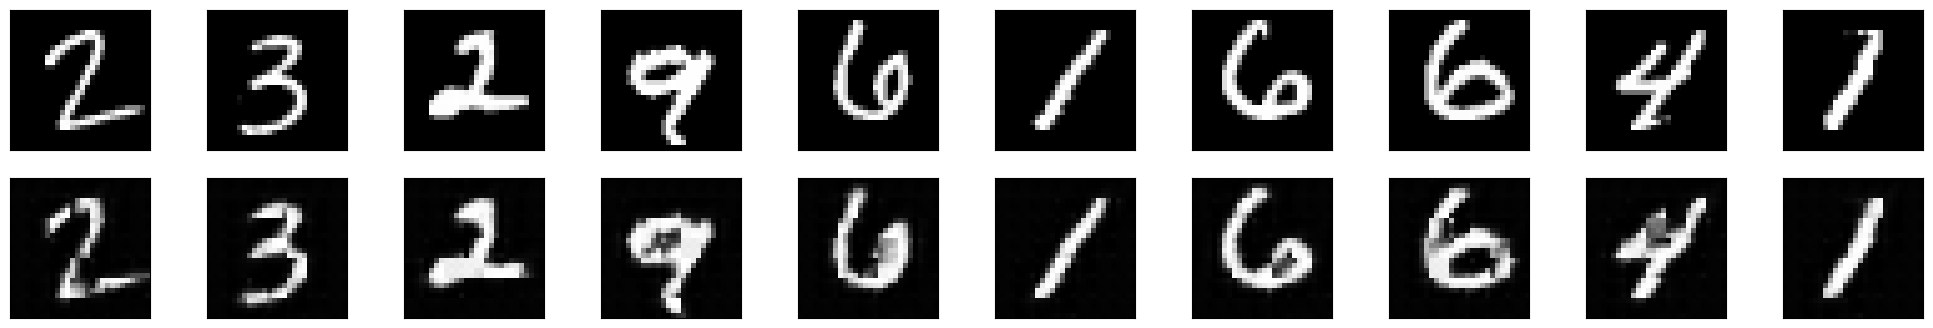

In [ ]:
model.encoder.save(base_location+'/TensorFlow/MNIST_CAE/Encoder_model')
encoderModel = tf.keras.models.load_model(base_location+'/TensorFlow/MNIST_CAE/Encoder_model')
encoderModel.summary()

# obtain one batch of test images
images = next(dataiter)

#using SavedModel to get latent vector
latent = encoderModel(images)
lat = tf.transpose(latent, perm=[0,3,1,2])
print(lat.shape)
print(lat[0])

#using original decoder model part
output = model.decoder(latent)
output = tf.transpose(output, perm=[0,3,1,2])
print(output.shape)
images = images.numpy()
fig, axes = plt.subplots(nrows=2, ncols=10, sharex=True, sharey=True, figsize=(25,4))

for images, row in zip([images, output], axes):
    for img, ax in zip(images, row):
        ax.imshow(np.squeeze(img), cmap='gray')
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)




